In [39]:
import vtk
from pathlib import Path
from scipy.stats import multivariate_normal
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from scipy import io as scio

In [40]:
#variables
path_to_processed_cohort = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir"

result_mean_mesh = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/average_nl_mesh.obj"

result_energies = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/workdir/deviation_energies.mat"

read meshes

In [45]:
def compute_center_of_mesh(mesh):
    centerOfMassFilter = vtk.vtkCenterOfMass()
    centerOfMassFilter.SetInputData(mesh)
    centerOfMassFilter.SetUseScalarsAsWeights(False)
    centerOfMassFilter.Update();
    center = centerOfMassFilter.GetCenter()
    return center




reader = vtk.vtkOBJReader()
num_of_points = 0
meshes_dict = {}
for path in tqdm(list(Path(path_to_processed_cohort).iterdir())):
    mesh_file = path / "head_affine_registered.obj"
    if not mesh_file.exists():
        continue
    reader.SetFileName(mesh_file)
    reader.Update()
    mesh = reader.GetOutput()
    points = mesh.GetPoints()
    center_of_mesh = np.array( compute_center_of_mesh(mesh) )
    num_of_points = points.GetNumberOfPoints()
    res_mesh = []
    for i in range(points.GetNumberOfPoints()):
        pt = points.GetPoint(i)
        res_mesh.append(list( np.array( pt) - center_of_mesh ))
    meshes_dict[str( mesh_file.parent.name ) ] = res_mesh


  0%|          | 0/778 [00:00<?, ?it/s]

Analyse statistics

In [46]:
def compute_descriptive_statistics(points):
    mean = np.mean(points, axis=0)
    std_dev = np.std(points, axis=0)
    robud
    # Add any other statistics you're interested in
    return mean, std_dev

### #read compute stats for each pointset:
stats = []
for i in tqdm(range(num_of_points)): # i in range of num_of_points
    index = []
    points = []
    for key, mesh_v in meshes_dict.items():
        index.append(key)
        points.append(mesh_v[i])
    df = pd.DataFrame( data = points, index=index, columns=['x','y','z'])
    stats.append(df.describe())



  0%|          | 0/25680 [00:00<?, ?it/s]

In [15]:
stds = [x.loc['std'].sum() for x in stats] # energies 

In [47]:
#mean mesh

points = [ [x.loc['mean']['x'], x.loc['mean']['y'], x.loc['mean']['z'] ] for x in stats ]
vtkpoints = vtk.vtkPoints()

i = 0 
for x in points:
    vtkpoints.InsertNextPoint(x)
    # Compute the color from the color map based on the energy value

mesh = reader.GetOutput()
mesh.SetPoints(vtkpoints) # add points 
mesh.GetPointData().SetScalars(colors) #set colors
writer = vtk.vtkOBJWriter()
writer.SetInputData(mesh)
writer.SetFileName(result_mean_mesh)
writer.Write()



polygons = mesh.GetPolys()
faces = []
# Iterate over the polygons to extract the faces
polygons.InitTraversal()
while True:
    faceIds = vtk.vtkIdList()
    if polygons.GetNextCell(faceIds):
        face = [faceIds.GetId(i) for i in range(faceIds.GetNumberOfIds())]
        faces.append(face)
    else:
        break
        
### compute colors and write to mat 
energies = []
for x in faces:
    en = 0 
    for p in x:
        en+= stds[p]
    energies.append(en)

scio.savemat(result_energies, {"energies": energies})


In [17]:
w

,0
count,25680.000000
mean,0.464514
std,0.203660
min,0.157181
25%,0.297019
50%,0.433105
75%,0.577960
max,1.265332


In [19]:
stats[0].loc['mean']['x']

-0.5271125688251843

<AxesSubplot:>

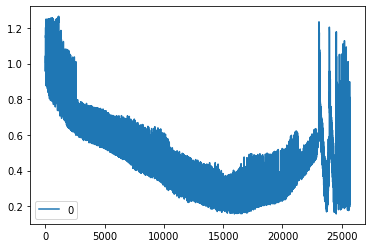

In [26]:
pd.DataFrame(stds).plot()

In [21]:
color_map = vtk.vtkColorTransferFunction()
color_map.SetColorSpaceToHSV()

In [31]:
renderer = vtk.vtkRenderer()
renderer.AddVolume(mesh)
render_window = vtk.vtkRenderWindow()
render_window.AddRenderer(renderer)


# Add the actor to the renderer
renderer.AddActor(actor)

# Render the scene and start the interaction
render_window.Render()

TypeError: AddVolume argument 1: method requires a vtkProp, a vtkPolyData was provided.

In [37]:
len(stds)

25680

In [38]:
len(meshes_dict)

299

In [41]:
[1.3,4,5] - [1,1,1]

TypeError: unsupported operand type(s) for -: 'list' and 'list'